Importing packages

In [8]:
import pandas as pd
import matplotlib.pyplot as plt

Creating required variables

In [9]:
Line_Numbers_Maastricht_Heerlen = ("32", "189")
Line_Numbers_DenBosch_Utrecht = ("88", "27", "29", "35", "39", "60")
Line_Numbers_Roosendaal_Dordrecht = ("59", "22", "23")

In [19]:
Filtered_2022 = pd.read_csv("data/Actual_Services_data/2022-utr-db.csv.gz")
Filtered_Jan_2023 = pd.read_csv("data/Actual_Services_data/jan-2023-mst-hrl.csv")
Filtered_Jul_2023 = pd.read_csv("data/Actual_Services_data/jul-2023-dor-roo.csv")
Filtered_Jun_2025 = pd.read_csv("data/Actual_Services_data/jun-2025-dor-roo.csv")
Filtered_Oct_2025 = pd.read_csv("data/Actual_Services_data/oct-2025-mst-hrl.csv")
Filtered_Nov_2025 = pd.read_csv("data/Actual_Services_data/nov-2025-utr-db.csv")

Creating the plots

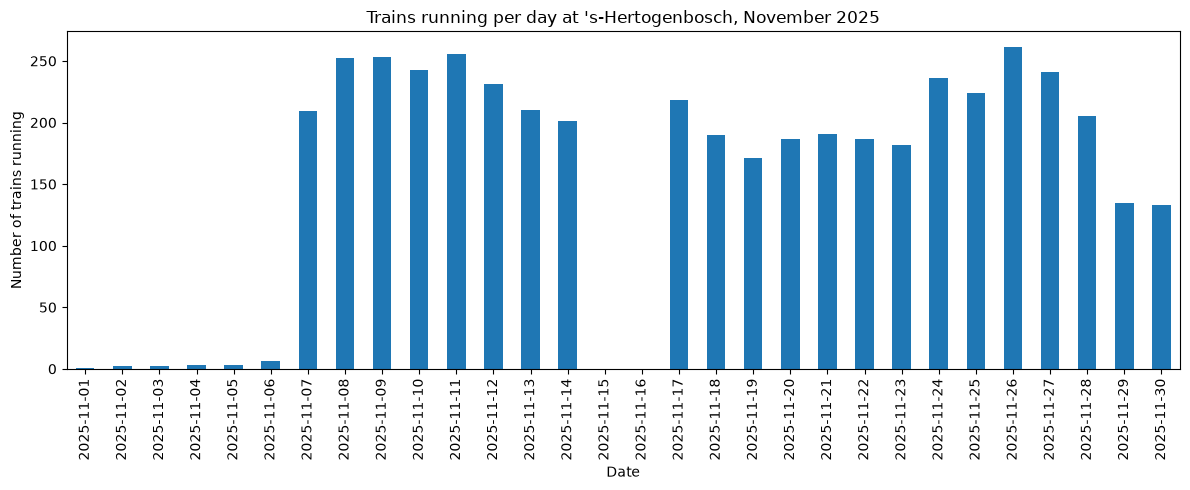

In [11]:
# Pick a station
station = "'s-Hertogenbosch"

# Keep only the rows for that station
df = Filtered_Nov_2025[Filtered_Nov_2025["Stop:Station name"] == station].copy()
df["Service:Date"] = pd.to_datetime(df["Service:Date"]).dt.date

# Keep only trains that were not completely cancelled, count them per day
running = df[df["Service:Partly cancelled"] == False]
trains_per_day = running.groupby("Service:Date")["Service:RDT-ID"].nunique()

# Include days with zero running trains
all_days = pd.date_range(df["Service:Date"].min(), df["Service:Date"].max()).date
trains_per_day = trains_per_day.reindex(all_days, fill_value=0)

# Plot
trains_per_day.plot(kind="bar", figsize=(12, 5))
plt.xlabel("Date")
plt.ylabel("Number of trains running")
plt.title(f"Trains running per day at {station}, November 2025")
plt.tight_layout()
plt.savefig("figures/Nov25-DenBosch.png", dpi=300, bbox_inches="tight")
plt.show()

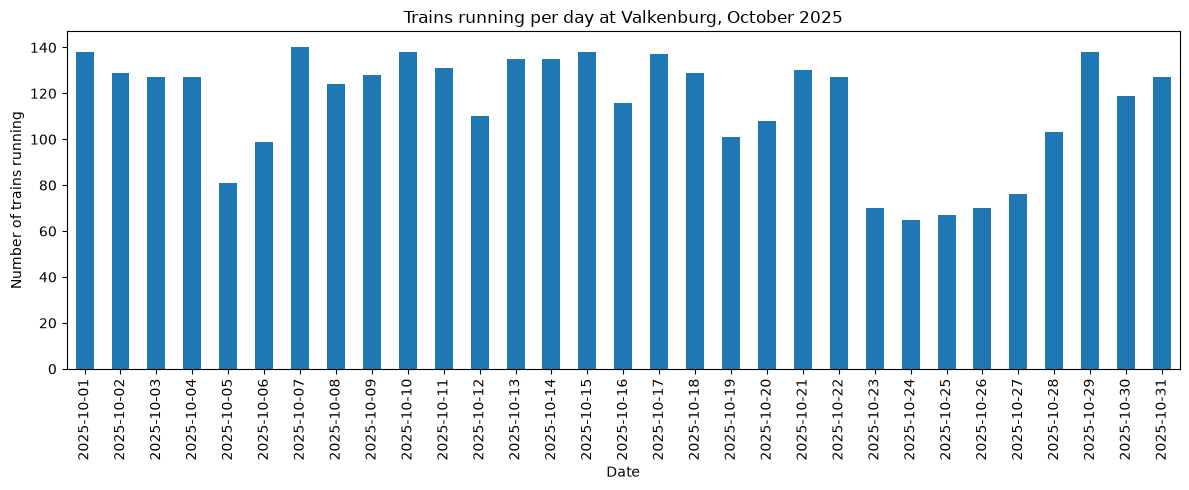

In [ ]:
# Pick a station
station = "Valkenburg"

# Keep only the rows for that station
df = Filtered_Oct_2025[Filtered_Oct_2025["Stop:Station name"] == station].copy()
df["Service:Date"] = pd.to_datetime(df["Service:Date"]).dt.date

# Keep only trains that were not completely cancelled, count them per day
running = df[df["Service:Partly cancelled"] == False]
trains_per_day = running.groupby("Service:Date")["Service:RDT-ID"].nunique()

# Include days with zero running trains
all_days = pd.date_range(df["Service:Date"].min(), df["Service:Date"].max()).date
trains_per_day = trains_per_day.reindex(all_days, fill_value=0)

# Plot
trains_per_day.plot(kind="bar", figsize=(12, 5))
plt.xlabel("Date")
plt.ylabel("Number of trains running")
plt.title(f"Trains running per day at {station}, October 2025")
plt.tight_layout()
plt.savefig("figures/Oct25-Valkenburg.png", dpi=300, bbox_inches="tight")
plt.show()

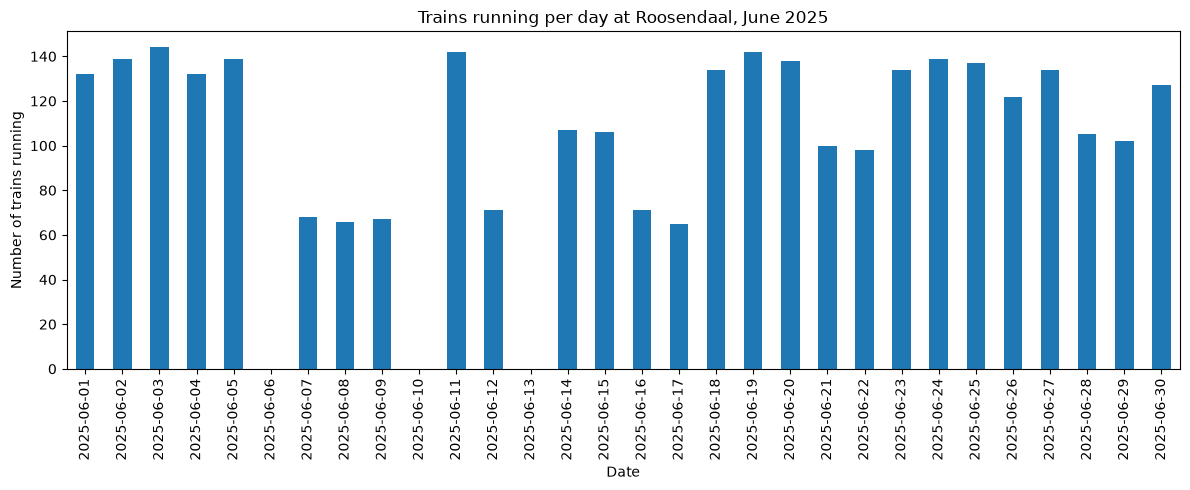

In [ ]:

# Pick a station
station = "Roosendaal"

# Keep only the rows for that station
df = Filtered_Jun_2025[Filtered_Jun_2025["Stop:Station name"] == station].copy()
df["Service:Date"] = pd.to_datetime(df["Service:Date"]).dt.date

# Keep only trains that were not completely cancelled, count them per day
running = df[df["Service:Partly cancelled"] == False]
trains_per_day = running.groupby("Service:Date")["Service:RDT-ID"].nunique()

# Include days with zero running trains
all_days = pd.date_range(df["Service:Date"].min(), df["Service:Date"].max()).date
trains_per_day = trains_per_day.reindex(all_days, fill_value=0)

# Plot
trains_per_day.plot(kind="bar", figsize=(12, 5))
plt.xlabel("Date")
plt.ylabel("Number of trains running")
plt.title(f"Trains running per day at {station}, June 2025")
plt.tight_layout()
plt.savefig("figures/Jun25-Roosendaal.png", dpi=300, bbox_inches="tight")
plt.show()

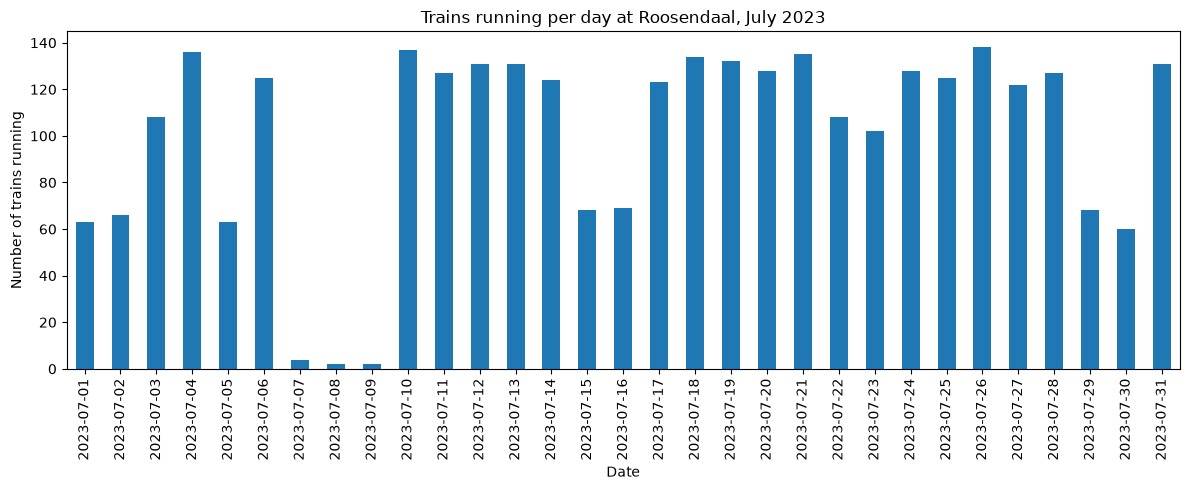

In [16]:
# Pick a station
station = "Roosendaal"

# Keep only the rows for that station
df = Filtered_Jul_2023[Filtered_Jul_2023["Stop:Station name"] == station].copy()
df["Service:Date"] = pd.to_datetime(df["Service:Date"]).dt.date

# Keep only trains that were not completely cancelled, count them per day
running = df[df["Service:Partly cancelled"] == False]
trains_per_day = running.groupby("Service:Date")["Service:RDT-ID"].nunique()

# Include days with zero running trains
all_days = pd.date_range(df["Service:Date"].min(), df["Service:Date"].max()).date
trains_per_day = trains_per_day.reindex(all_days, fill_value=0)

# Plot
trains_per_day.plot(kind="bar", figsize=(12, 5))
plt.xlabel("Date")
plt.ylabel("Number of trains running")
plt.title(f"Trains running per day at {station}, July 2023")
plt.tight_layout()
plt.savefig("figures/Jul23-Roosendaal.png", dpi=300, bbox_inches="tight")
plt.show()

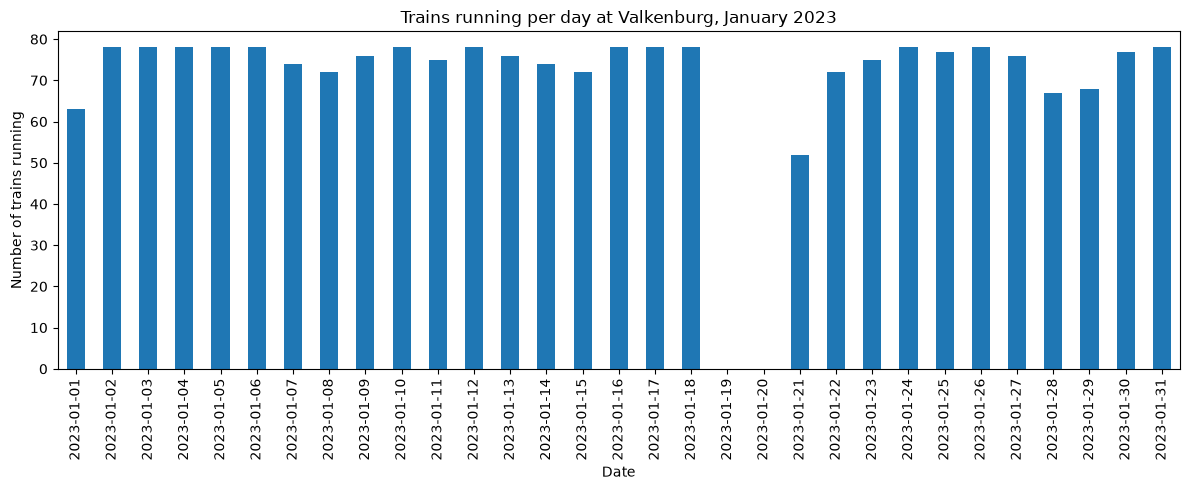

In [17]:
# Pick a station
station = "Valkenburg"

# Keep only the rows for that station
df = Filtered_Jan_2023[Filtered_Jan_2023["Stop:Station name"] == station].copy()
df["Service:Date"] = pd.to_datetime(df["Service:Date"]).dt.date

# Keep only trains that were not completely cancelled, count them per day
running = df[df["Service:Partly cancelled"] == False]
trains_per_day = running.groupby("Service:Date")["Service:RDT-ID"].nunique()

# Include days with zero running trains
all_days = pd.date_range(df["Service:Date"].min(), df["Service:Date"].max()).date
trains_per_day = trains_per_day.reindex(all_days, fill_value=0)

# Plot
trains_per_day.plot(kind="bar", figsize=(12, 5))
plt.xlabel("Date")
plt.ylabel("Number of trains running")
plt.title(f"Trains running per day at {station}, January 2023")
plt.tight_layout()
plt.savefig("figures/Jan23-Valkenburg.png", dpi=300, bbox_inches="tight")
plt.show()

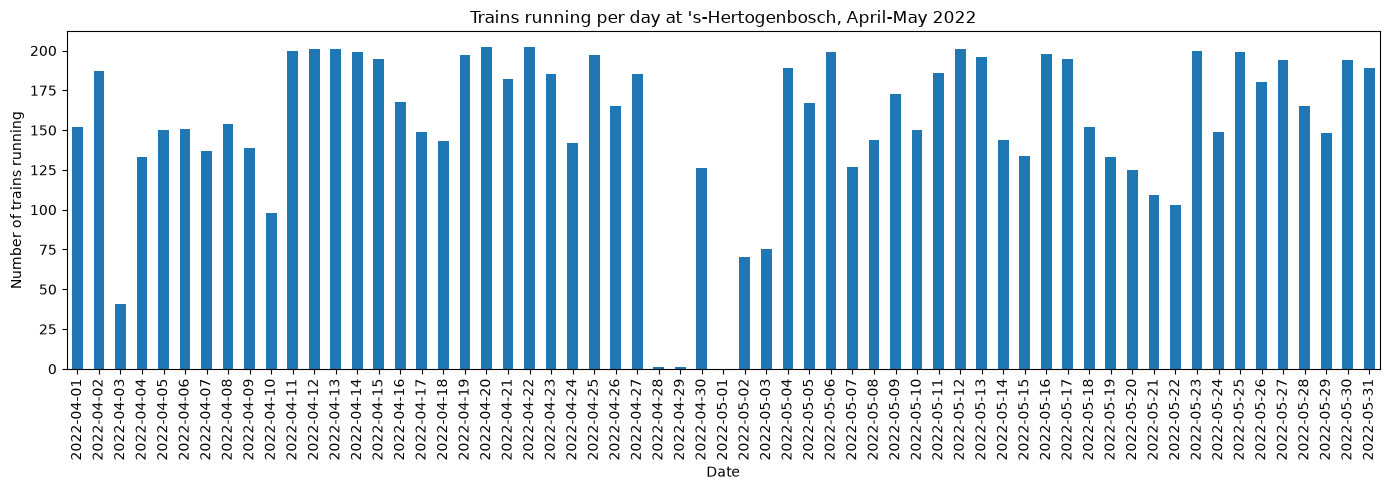

In [21]:
station = "'s-Hertogenbosch"

# Keep only the rows for that station
df = Filtered_2022[Filtered_2022["Stop:Station name"] == station].copy()

# Make the date a real date, then keep only April and May 2022
df["Service:Date"] = pd.to_datetime(df["Service:Date"])
start = "2022-04-01"
end = "2022-05-31"
df = df[(df["Service:Date"] >= start) & (df["Service:Date"] <= end)]
df["Service:Date"] = df["Service:Date"].dt.date

# Keep only trains that were not completely cancelled, count them per day
running = df[df["Service:Partly cancelled"] == False]
trains_per_day = running.groupby("Service:Date")["Service:RDT-ID"].nunique()

# Include days with zero running trains (every day from 1 April to 31 May)
all_days = pd.date_range(start, end).date
trains_per_day = trains_per_day.reindex(all_days, fill_value=0)

# Plot
trains_per_day.plot(kind="bar", figsize=(14, 5))
plt.xlabel("Date")
plt.ylabel("Number of trains running")
plt.title(f"Trains running per day at {station}, April-May 2022")
plt.tight_layout()
plt.savefig("figures/22-DenBosch.png", dpi=300, bbox_inches="tight")
plt.show()